In [1]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 8.0 MB/s eta 0:00:00 MB/s eta 0:00:01:020m

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import numpy
import scipy
import sklearn
import xgboost

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

Python: 3.12.4
NumPy: 2.5.3
SciPy: 1.18.1
scikit-learn: 1.9.0
XGBoost: 3.4.1


## 클래스 설계안

### 1. 클래스 목록

손동작 4종과 팔꿈치 각도 2종을 조합하여 총 8개 클래스로 구성한다.

| 클래스 | 손동작 | 팔꿈치 각도 |
|---|---|---|
| 30F | 주먹 쥐기 | 30° |
| 30O | 손 펴기 | 30° |
| 30P | 회내: 손등이 위로 향하도록 전완 회전 | 30° |
| 30S | 회외: 손바닥이 위로 향하도록 전완 회전 | 30° |
| 60F | 주먹 쥐기 | 60° |
| 60O | 손 펴기 | 60° |
| 60P | 회내: 손등이 위로 향하도록 전완 회전 | 60° |
| 60S | 회외: 손바닥이 위로 향하도록 전완 회전 | 60° |

### 2. 채널과 근육의 대응

| 채널 | 측정 근육 | 부착 부위 |
|---|---|---|
| Ch 1 | 요측수근신근(ECR) | 전완 후면 |
| Ch 2 | 총지신근(ED) | 전완 후면 |
| Ch 3 | 천지굴근(FDS) | 전완 전면 |
| Ch 4 | 상완이두근(Biceps) | 상완 전면 |
| Ch 5 | 상완삼두근(Triceps) | 상완 후면 |

### 3. 설계 근거

같은 손동작이라도 팔꿈치 각도에 따라 근육의 사용과 sEMG 신호가 달라질 수 있다.
따라서 손동작과 각도를 조합한 클래스를 사용하여 두 정보를 한 번에 예측하도록 설계한다.

### 4. 따로 예측하는 방식과 비교

8클래스 방식은 하나의 예측 결과로 손동작과 각도를 함께 알 수 있다는 장점이 있다.
하지만 동작이나 각도 종류가 늘어나면 클래스 수가 빠르게 증가한다.

손동작과 각도를 따로 예측하면 각각의 오류를 구분하여 분석하기 쉽다.
다만 두 예측 결과를 결합해야 하며, 두 정보가 모두 맞았는지도 평가해야 한다.

### 5. 각도 조건을 늘릴 때의 문제

각도를 3종으로 늘리면 12클래스, 4종으로 늘리면 16클래스가 된다.
클래스마다 충분한 데이터를 모으려면 측정 시간과 반복 횟수가 늘어난다.
또한 가까운 각도 사이에서는 신호 차이가 작아 구분이 어려울 수 있다.

## 사용 데이터 및 실습 범위

본 실습에서는 원 논문의 데이터 대신 공개 데이터인 Ninapro DB2를
사용하였다. 피험자 1의 S1_E1_A1.mat 파일을 불러와 분석하였다.

| 항목 | 내용 |
|---|---|
| 데이터셋 | Ninapro DB2 |
| 사용 피험자 | 피험자 1 |
| 파일명 | S1_E1_A1.mat |
| sEMG 데이터 크기 | 1,808,331 × 12 |
| 채널 수 | 12개 |
| 샘플링 주파수 | 2,000 Hz |
| 선택한 동작 수 | 4개 |
| 동작별 반복 수 | 6회 |
| 선택한 동작의 전체 반복 수 | 24회 |

선택한 동작은 손가락 벌리기(ID 5), 주먹 쥐기(ID 6),
회외(ID 9), 회내(ID 10)이다.
동작 구간은 restimulus, 반복 번호는 rerepetition을 기준으로 확인하였다.
휴식 구간인 동작 ID 0은 동작별 집계에서 제외하였다.

이번 실습에서는 데이터 구조 확인, 동작별 데이터 요약,
12개 채널 시각화, 네 가지 동작의 신호 비교를 수행하였다.
신호는 별도의 필터링이나 정규화 없이 불러온 값으로 시각화하였다.
모델 학습과 분류 성능 평가는 수행하지 않았다.

## 원 논문과 실제 실습의 차이

원 논문의 클래스 설계는 네 가지 동작과 두 가지 팔꿈치 각도를
조합한 8개 클래스이다. 앞에서 작성한 8개 클래스 설계와
5개 채널 설명은 원 논문을 기준으로 정리한 내용이다.

실제 실습에서는 12채널 공개 데이터를 사용하였다.
30°와 60°의 팔꿈치 각도 조건 라벨을 확보하지 못했으므로,
각도를 구분하지 않고 네 가지 동작을 비교하였다.
따라서 이번 결과는 원 논문의 8개 클래스 실험을 그대로 재현한
결과가 아니라 공개 데이터를 활용한 대체 실습 결과이다.

데이터 출처: https://ninapro.hevs.ch/instructions/DB2.html

In [3]:
from pathlib import Path
from scipy.io import loadmat
import numpy as np

data_path = Path("/Users/ala/Downloads/DB2_s1/S1_E1_A1.mat")
mat = loadmat(data_path)

print("File:", data_path.name)

for name, value in mat.items():
    if not name.startswith("__"):
        print(name, "→", np.shape(value))

File: S1_E1_A1.mat
emg → (1808331, 12)
acc → (1808331, 36)
stimulus → (1808331, 1)
glove → (1808331, 22)
inclin → (1808331, 2)
subject → (1, 1)
exercise → (1, 1)
repetition → (1808331, 1)
restimulus → (1808331, 1)
rerepetition → (1808331, 1)


In [4]:
import pandas as pd

FS = 2000  # Ninapro DB2 sampling rate in Hz

emg = mat["emg"]
labels = mat["restimulus"].ravel().astype(int)
repetitions = mat["rerepetition"].ravel().astype(int)

print("Subject:", mat["subject"].item())
print("Exercise:", mat["exercise"].item())
print("EMG shape:", emg.shape)
print("Recording duration (seconds):", round(len(emg) / FS, 2))
print("Movement labels:", np.unique(labels))

rows = []

for label in np.unique(labels):
    if label == 0:
        continue  # Rest, not a movement class

    mask = labels == label
    reps = np.unique(repetitions[mask])
    reps = reps[reps > 0]

    rows.append({
        "Movement ID": label,
        "Repetitions": len(reps),
        "Samples": int(mask.sum()),
        "Total duration (s)": round(mask.sum() / FS, 2)
    })

summary = pd.DataFrame(rows)
display(summary)

Subject: 1
Exercise: 1
EMG shape: (1808331, 12)
Recording duration (seconds): 904.17
Movement labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


,Movement ID,Repetitions,Samples,Total duration (s)
0,1,6,78701,39.35
1,2,6,58979,29.49
2,3,6,50985,25.49
3,4,6,45065,22.53
4,5,6,40125,20.06
5,6,6,25557,12.78
6,7,6,58155,29.08
7,8,6,28238,14.12
8,9,6,39903,19.95
9,10,6,45174,22.59


Matplotlib is building the font cache; this may take a moment.


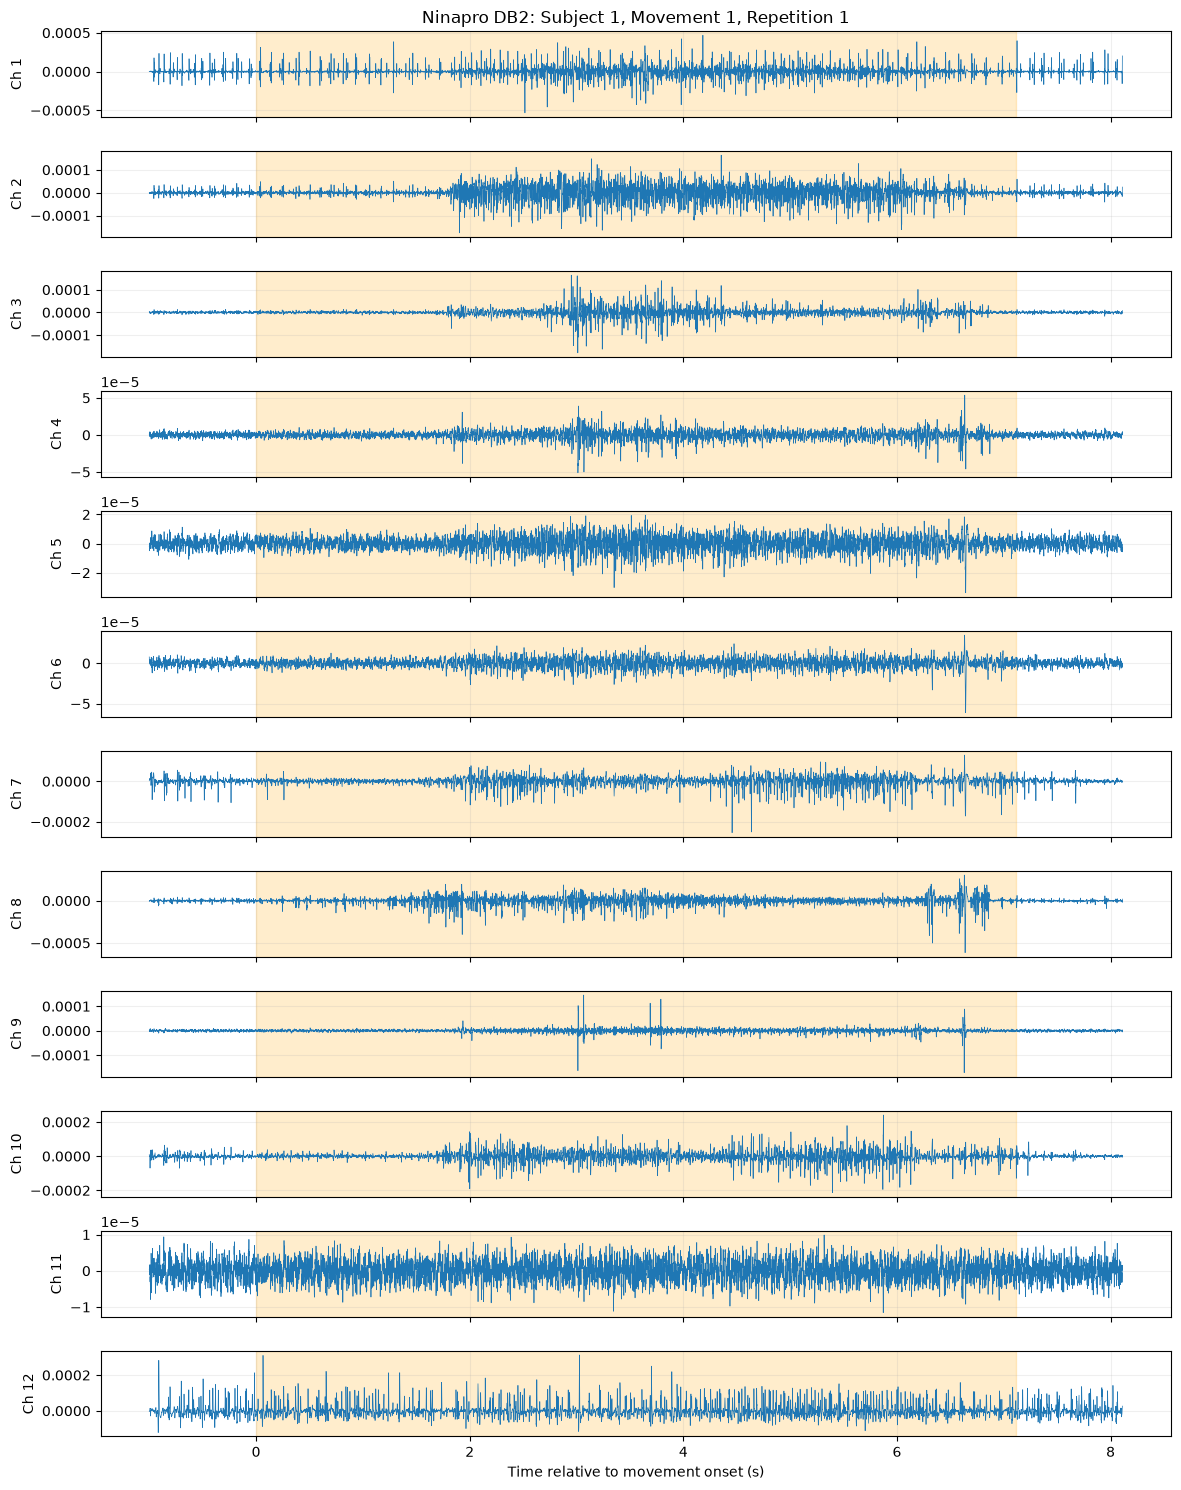

Movement segment shape: (14221, 12)
Movement duration (s): 7.11


In [5]:
import matplotlib.pyplot as plt

# Locate movement 1, repetition 1
mask = (labels == 1) & (repetitions == 1)
indices = np.flatnonzero(mask)

if len(indices) == 0:
    raise ValueError("Movement 1, repetition 1 was not found.")

# Use the first continuous movement segment
breaks = np.flatnonzero(np.diff(indices) > 1)
start = indices[0]
end = indices[breaks[0]] + 1 if len(breaks) else indices[-1] + 1

# Include one second before and after the movement
left = max(0, start - FS)
right = min(len(emg), end + FS)

time = (np.arange(left, right) - start) / FS
movement_duration = (end - start) / FS

fig, axes = plt.subplots(
    12, 1, figsize=(12, 15), sharex=True
)

for ch, ax in enumerate(axes):
    ax.plot(time, emg[left:right, ch], linewidth=0.5)
    ax.axvspan(
        0, movement_duration,
        color="orange", alpha=0.2
    )
    ax.set_ylabel(f"Ch {ch + 1}")
    ax.grid(alpha=0.2)

axes[0].set_title(
    "Ninapro DB2: Subject 1, Movement 1, Repetition 1"
)
axes[-1].set_xlabel("Time relative to movement onset (s)")

plt.tight_layout()
plt.savefig("week4_emg_12channels.png", dpi=150)
plt.show()

print("Movement segment shape:", emg[start:end].shape)
print("Movement duration (s):", round(movement_duration, 3))

## 채널별 신호 관찰

Ninapro DB2의 피험자 1, 동작 ID 1, 첫 번째 반복 데이터를
사용하여 12개 채널의 sEMG 신호를 시각화하였다.
주황색 영역은 restimulus 라벨을 기준으로 표시한 동작 구간이다.

채널 2와 채널 10에서는 표시된 동작 구간의 일부에서
신호 진폭의 변화가 뚜렷하게 증가하였다.
반면 채널 11에서는 구간 전후의 변화가 상대적으로 작게 보였다.
이를 통해 같은 동작에서도 채널마다 신호 변화 양상이 다름을 확인하였다.

각 그래프의 세로축 범위가 다르므로 파형의 화면상 높이만으로
채널 간 신호 크기를 비교하지 않았다.
또한 라벨 구간 전체에서 모든 채널이 동일하게 활성화되는 것은 아니었다.

본 실습은 원 논문의 5채널 데이터 대신 12채널 공개 데이터를 사용하였다.
30°와 60°의 팔꿈치 각도 조건에 해당하는 라벨을 확보하지 못했으므로,
두 각도의 신호 차이는 분석하지 않았다.

In [6]:
movement_names = {
    5: "Finger spreading",
    6: "Fist",
    9: "Supination",
    10: "Pronation"
}

selected_ids = list(movement_names)

selected_summary = summary[
    summary["Movement ID"].isin(selected_ids)
].copy()

selected_summary.insert(
    1,
    "Movement",
    selected_summary["Movement ID"].map(movement_names)
)

display(selected_summary.reset_index(drop=True))

print("Selected classes:", len(selected_ids))
print("Total repetitions:", selected_summary["Repetitions"].sum())

,Movement ID,Movement,Repetitions,Samples,Total duration (s)
0,5,Finger spreading,6,40125,20.06
1,6,Fist,6,25557,12.78
2,9,Supination,6,39903,19.95
3,10,Pronation,6,45174,22.59


Selected classes: 4
Total repetitions: 24


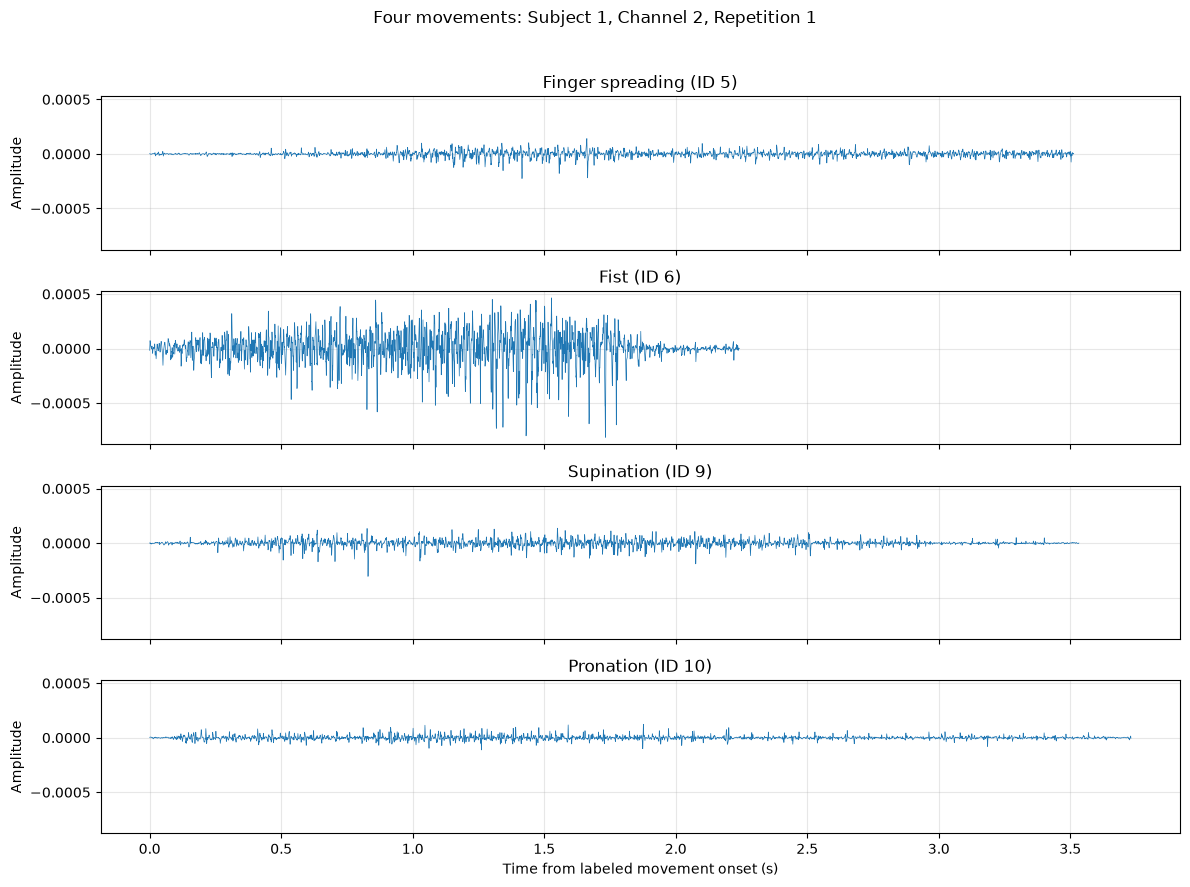

In [7]:
import matplotlib.pyplot as plt

channel = 1  # Python index 1 = Channel 2

fig, axes = plt.subplots(
    4, 1, figsize=(12, 9), sharex=True, sharey=True
)

for ax, movement_id in zip(axes, selected_ids):
    indices = np.flatnonzero(
        (labels == movement_id) & (repetitions == 1)
    )

    if len(indices) == 0:
        raise ValueError(f"No data for movement {movement_id}")

    # Keep the first continuous segment
    breaks = np.flatnonzero(np.diff(indices) > 1)
    start = indices[0]
    end = (
        indices[breaks[0]] + 1
        if len(breaks)
        else indices[-1] + 1
    )

    signal = emg[start:end, channel]
    t = np.arange(len(signal)) / FS

    ax.plot(t, signal, linewidth=0.5)
    ax.set_title(
        f"{movement_names[movement_id]} (ID {movement_id})"
    )
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time from labeled movement onset (s)")
fig.suptitle("Four movements: Subject 1, Channel 2, Repetition 1")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("week4_four_movements.png", dpi=150)
plt.show()

## 네 가지 동작의 신호 비교

피험자 1의 채널 2에서 네 가지 동작의 첫 번째 반복 신호를 비교하였다.
모든 그래프의 세로축 범위를 동일하게 설정하여 진폭을 비교하였다.

이번 예시에서는 주먹 쥐기(Fist)의 신호 진폭이 다른 세 동작보다
크게 나타났다. 손가락 벌리기(Finger spreading)는 일부 구간에서
신호가 증가했으며, 회외(Supination)와 회내(Pronation)는
주먹 쥐기보다 상대적으로 작은 진폭을 보였다.
동작별로 신호가 변화하는 시점과 라벨 구간의 길이도 달랐다.

이 결과는 한 피험자의 한 채널과 첫 번째 반복에 대한 관찰이므로,
모든 피험자와 반복에서 동일한 차이가 나타난다고 판단할 수는 없다.

본 데이터에는 과제에서 요구한 팔꿈치 각도 30°와 60°의 조건 라벨이
없으므로, 각도 비교 대신 네 가지 동작의 신호를 비교하였다.

## 최종 결과 및 느낀 점

이번 실습에서는 Ninapro DB2 피험자 1의 데이터를 불러와
데이터 구조와 동작별 반복 수를 확인하였다.
12개 채널의 신호를 시각화하고, 네 가지 동작의 신호를 비교하였다.

채널별로 신호가 변화하는 양상이 달랐으며, 채널 2의 첫 번째
반복에서는 주먹 쥐기의 진폭이 다른 세 동작보다 크게 나타났다.
이를 통해 같은 채널에서도 동작에 따라 신호의 크기와 형태가
달라질 수 있음을 확인하였다.

다만 한 피험자의 일부 신호를 관찰한 결과이므로,
이를 모든 사람과 반복에 일반화하기는 어렵다.
또한 팔꿈치 각도 라벨이 없어 30°와 60°의 차이는 비교하지 못하였다.

이번 실습을 통해 모델을 학습하기 전에 데이터의 구조,
라벨, 채널 수를 정확하게 확인하는 과정이 필요하다는 것을 배웠다.